**[🏠 Course Home](00_START_HERE.ipynb)** | **🤖 [AI-Native](../ai/13_hierarchical_models_and_partial_pooling.ipynb)** | **📖 [Conceptual](../conceptual/13_hierarchical_models_and_partial_pooling.ipynb)** | **🐍 [Python](../python/13_hierarchical_models_and_partial_pooling.ipynb)** | **⬅️ [Prev: Ch 12: Bayesian Regression, Counts & GLMs](12_bayesian_regression_and_glms.ipynb)** | **➡️ [Next: Ch 14: Marginal Likelihood & Occam's Razor](14_marginal_likelihood_and_model_comparison.ipynb)**

*🧭 Part III: Applied Modeling, Regression, Hierarchy & Model Comparison — Chapter 13 of 22*

---

# Chapter 13: Hierarchical Models, Partial Pooling & Shrinkage (R Track)
### *Borrowing Strength Across Multi-Group Architectures*

In Sheets 1 through 7, we focused primarily on single-parameter models or simple
two-sample comparisons. In real-world production engineering, however, we
regularly monitor hundreds of clusters, microservices, or test suites
simultaneously, each with radically different sample sizes.

In this chapter, we implement:
1. The multi-group dilemma across $J = 12$ production clusters with highly
   unbalanced sample sizes ($n_j \in [3, 400]$).
2. The three pooling estimators (No Pooling, Complete Pooling, Partial Pooling).
3. The iconic **Shrinkage Arrow Dashboard** and out-of-sample RMSE validation.
4. **3-Tier Scaffolding Exercises**:
   - 🟢 Tier 1: Hand-calculating shrinkage weights $w_j$ and posterior means.
- 🟡 Tier 2: Empirical Bayes Beta-Binomial hierarchical pooling for test suites.
   - 🔴 Tier 3: Hierarchical MCMC sampling exposing Neal's Funnel and the
     non-centered reparameterization.

---


## Part 1: The Multi-Group Dilemma ($J = 12$ Production Clusters)

Consider an infrastructure platform tracking average query latency across
$J = 12$ regional data centers.
- The global population mean latency is $\mu_{\text{pop}} = 50.0$ ms with
  between-cluster standard deviation $\tau_{\text{pop}} = 10.0$ ms.
- Individual query measurements suffer from observation noise $\sigma = 15.0$
ms.
- Sample sizes $n_j$ range from $3$ requests (newly deployed canary nodes) to
  $400$ requests (heavy primary clusters).

Below, we simulate ground-truth latent latencies $\theta_j^{\text{true}}$ and
noisy observations $y_{ji}$, displaying the resulting sample statistics.


In [1]:
# ==============================================================================
# Part 1: Simulating Multi-Group Production Cluster Data (J = 12 Clusters)
# ==============================================================================
set.seed(42)

# Global ground-truth population parameters
mu_pop_true <- 50.0   # Population mean latency (ms)
tau_pop_true <- 10.0  # Between-cluster variation (sd)
sigma_noise <- 15.0   # Within-cluster observation noise (sd)

# J = 12 clusters with highly unbalanced sample sizes
J <- 12
group_names <- sprintf("Cluster-%02d", 1:J)
n_samples <- c(3, 5, 8, 12, 15, 25, 40, 60, 100, 150, 250, 400)

# Draw true latent parameters from population distribution
theta_true <- rnorm(J, mean = mu_pop_true, sd = tau_pop_true)

# Generate observations for each cluster
observed_means <- numeric(J)
sample_ses <- numeric(J)
all_observations <- vector("list", J)

for (j in 1:J) {
  y_j <- rnorm(n_samples[j], mean = theta_true[j], sd = sigma_noise)
  all_observations[[j]] <- y_j
  observed_means[j] <- mean(y_j)
  sample_ses[j] <- sigma_noise / sqrt(n_samples[j])
}

cat(sprintf("%-10s %5s %12s %12s %9s\n",
            "Cluster", "N", "True Mean", "Sample Mean", "Std Err"))
cat(paste(rep("-", 52), collapse = ""), "\n")
for (j in 1:J) {
  cat(sprintf("%-10s %5d %12.2f %12.2f %9.2f\n",
              group_names[j], n_samples[j], theta_true[j],
              observed_means[j], sample_ses[j]))
}


Cluster        N    True Mean  Sample Mean   Std Err


---------------------------------------------------- 


Cluster-01     3        63.71        54.70      8.66
Cluster-02     5        44.35        34.08      6.71
Cluster-03     8        53.63        50.63      5.30
Cluster-04    12        56.33        51.55      4.33
Cluster-05    15        54.04        55.69      3.87
Cluster-06    25        48.94        49.87      3.00
Cluster-07    40        65.12        65.84      2.37
Cluster-08    60        49.05        46.96      1.94
Cluster-09   100        70.18        70.05      1.50
Cluster-10   150        49.37        48.90      1.22
Cluster-11   250        63.05        62.78      0.95
Cluster-12   400        72.87        72.04      0.75


---

## Part 2: The Three Pooling Paradigms in Code

We compare three estimation paradigms:
1. **No Pooling**: $\hat{\theta}_j^{\text{no}} = \bar{y}_j$ (Isolated sample
   means). Subject to massive variance when $n_j$ is small.
2. **Complete Pooling**: $\hat{\theta}_j^{\text{pool}} = \bar{y}_{\text{all}}$
   (Weighted grand mean). Erases real differences between clusters.
3. **Partial Pooling (Hierarchical Bayes)**:
$$\hat{\theta}_j^{\text{partial}} = w_j \bar{y}_j + (1 - w_j) \mu_{\text{pop}},
\quad w_j = \frac{n_j}{n_j + \kappa}$$
   where $\kappa = \sigma^2 / \tau_{\text{pop}}^2 = 15^2 / 10^2 = 2.25$.


In [2]:
# ==============================================================================
# Part 2: Implementing the Three Pooling Paradigms & Computing Errors
# ==============================================================================
# 1. No Pooling
theta_no_pool <- observed_means

# 2. Complete Pooling
total_obs <- sum(n_samples)
mu_complete_pool <- sum(n_samples * observed_means) / total_obs
theta_complete_pool <- rep(mu_complete_pool, J)

# 3. Partial Pooling (Hierarchical Bayes)
kappa <- (sigma_noise^2) / (tau_pop_true^2)  # kappa = 225 / 100 = 2.25
shrinkage_weights <- n_samples / (n_samples + kappa)
theta_partial_pool <- (shrinkage_weights * observed_means +
                       (1.0 - shrinkage_weights) * mu_pop_true)

# Root Mean Squared Error (RMSE) against ground-truth theta_true
rmse_no_pool <- sqrt(mean((theta_no_pool - theta_true)^2))
rmse_complete_pool <- sqrt(mean((theta_complete_pool - theta_true)^2))
rmse_partial_pool <- sqrt(mean((theta_partial_pool - theta_true)^2))

cat(sprintf("%-10s %4s %8s %9s %13s %14s\n",
            "Cluster", "N", "Weight",
            "No-Pool", "Partial-Pool", "Complete-Pool"))
cat(paste(rep("-", 62), collapse = ""), "\n")
for (j in 1:J) {
  cat(sprintf("%-10s %4d %8.3f %9.2f %13.2f %14.2f\n",
              group_names[j], n_samples[j], shrinkage_weights[j],
              theta_no_pool[j], theta_partial_pool[j], theta_complete_pool[j]))
}

cat("\n=== Estimation Error Across All J = 12 Clusters ===\n")
cat(sprintf("No Pooling RMSE:       %6.3f ms\n", rmse_no_pool))
cat(sprintf("Complete Pooling RMSE: %6.3f ms\n", rmse_complete_pool))
cat(sprintf("Partial Pooling RMSE:  %6.3f ms (Lowest Error!)\n",
            rmse_partial_pool))


Cluster       N   Weight   No-Pool  Partial-Pool  Complete-Pool


-------------------------------------------------------------- 


Cluster-01    3    0.571     54.70         52.69          63.43
Cluster-02    5    0.690     34.08         39.02          63.43
Cluster-03    8    0.780     50.63         50.49          63.43
Cluster-04   12    0.842     51.55         51.31          63.43
Cluster-05   15    0.870     55.69         54.95          63.43
Cluster-06   25    0.917     49.87         49.88          63.43
Cluster-07   40    0.947     65.84         65.00          63.43
Cluster-08   60    0.964     46.96         47.07          63.43
Cluster-09  100    0.978     70.05         69.61          63.43
Cluster-10  150    0.985     48.90         48.92          63.43
Cluster-11  250    0.991     62.78         62.67          63.43
Cluster-12  400    0.994     72.04         71.92          63.43



=== Estimation Error Across All J = 12 Clusters ===


No Pooling RMSE:        4.358 ms


Complete Pooling RMSE: 10.610 ms


Partial Pooling RMSE:   4.002 ms (Lowest Error!)


---

## Part 3 & 4: The Iconic Shrinkage Visualization Dashboard

We visualize the mechanics of partial pooling in two complementary views:
1. **The Shrinkage Arrow Plot**: Each cluster's No-Pooling sample mean
   $\bar{y}_j$ is plotted alongside its Partial-Pooling estimate
   $\hat{\theta}_j^{\text{partial}}$, connected by a directional arrow pointing
   toward the population mean $\mu_{\text{pop}}$. Notice how low-$N$ canaries
   experience massive shrinkage, while high-$N$ clusters barely budge.
2. **Prediction Error Profile**: Comparing absolute estimation errors
   $|\hat{\theta}_j - \theta_j^{\text{true}}|$ across clusters, demonstrating
   why Stein's paradox guarantees superior performance for partial pooling.


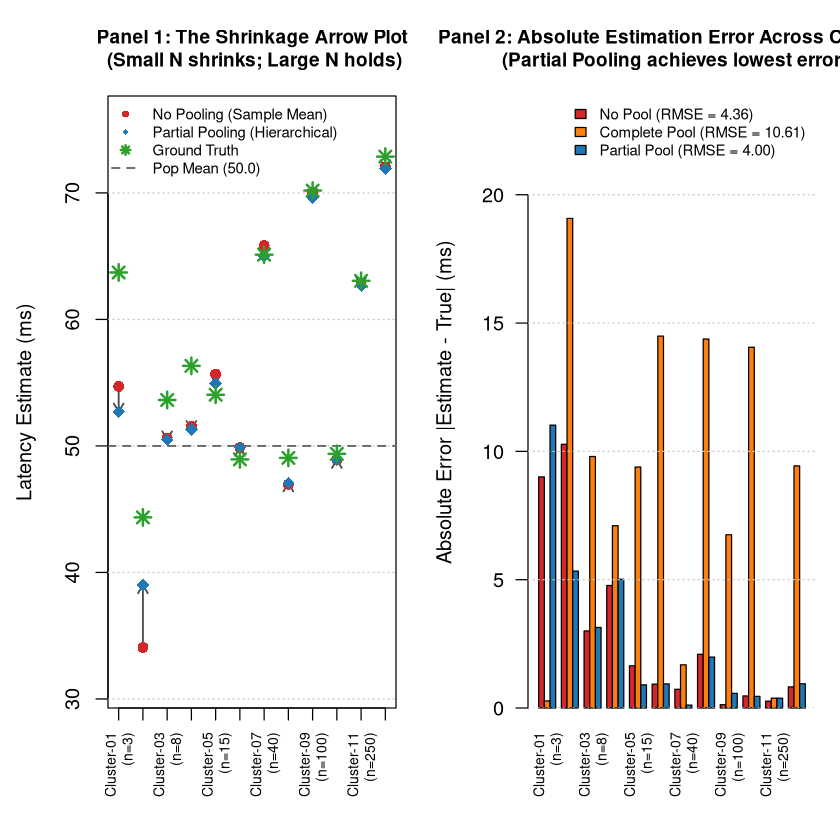

In [3]:
# ==============================================================================
# Part 4: The Iconic Shrinkage Visualization Dashboard (2-Panel Layout)
# ==============================================================================
par(mfrow = c(1, 2), mar = c(5.5, 4.5, 4, 1))

# --- Panel 1: The Shrinkage Arrow Plot ---
all_vals <- c(theta_no_pool, theta_partial_pool, theta_true, mu_pop_true)
y_lims <- range(all_vals) + c(-3, 3)
plot(1:J, theta_no_pool, type = "n", xaxt = "n", ylim = y_lims,
     xlab = "", ylab = "Latency Estimate (ms)",
     main = paste("Panel 1: The Shrinkage Arrow Plot
",
                  "(Small N shrinks; Large N holds)"),
     cex.main = 0.95, font.main = 2)

grid(nx = NA, ny = NULL, col = "gray80", lty = 3)
abline(h = mu_pop_true, col = "gray40", lty = 2, lwd = 1.5)

# Draw arrows from No-Pool to Partial-Pool
arrows(1:J, theta_no_pool, 1:J, theta_partial_pool,
       col = "gray30", length = 0.08, lwd = 1.5)

# Points
points(1:J, theta_no_pool, pch = 16, col = "#d62728", cex = 1.2)
points(1:J, theta_partial_pool, pch = 18, col = "#1f77b4", cex = 1.4)
points(1:J, theta_true, pch = 8, col = "#2ca02c", cex = 1.3, lwd = 2)

labels_x <- sprintf("%s\n(n=%d)", group_names, n_samples)
axis(1, at = 1:J, labels = labels_x, las = 2, cex.axis = 0.7)

legend("topleft", bty = "n", cex = 0.75,
       pch = c(16, 18, 8, NA), lty = c(NA, NA, NA, 2), lwd = c(NA, NA, 2, 1.5),
       col = c("#d62728", "#1f77b4", "#2ca02c", "gray40"),
       legend = c("No Pooling (Sample Mean)", "Partial Pooling (Hierarchical)",
                  "Ground Truth", sprintf("Pop Mean (%.1f)", mu_pop_true)))

# --- Panel 2: Absolute Error Comparison ---
err_no <- abs(theta_no_pool - theta_true)
err_complete <- abs(theta_complete_pool - theta_true)
err_partial <- abs(theta_partial_pool - theta_true)

err_mat <- rbind(err_no, err_complete, err_partial)
barplot(err_mat, beside = TRUE, col = c("#d62728", "#ff7f0e", "#1f77b4"),
        ylim = c(0, max(err_mat) * 1.25),
        names.arg = labels_x, las = 2, cex.names = 0.7,
        ylab = "Absolute Error |Estimate - True| (ms)",
        main = paste("Panel 2: Absolute Estimation Error Across Clusters
",
                     "(Partial Pooling achieves lowest error)"),
        cex.main = 0.95, font.main = 2)

grid(nx = NA, ny = NULL, col = "gray80", lty = 3)
legend("topright", bty = "n", cex = 0.75,
       fill = c("#d62728", "#ff7f0e", "#1f77b4"),
       legend = c(sprintf("No Pool (RMSE = %.2f)", rmse_no_pool),
                  sprintf("Complete Pool (RMSE = %.2f)", rmse_complete_pool),
                  sprintf("Partial Pool (RMSE = %.2f)", rmse_partial_pool)))


---

## Part 5: 3-Tier Scaffolding Exercises

Practice the mathematical principles of hierarchical shrinkage and
parameterization
across three graduated challenge tiers:
* 🟢 **Tier 1 (Warmup / Mental Math)**: Hand-calculating the shrinkage weight
  $w_j$ and posterior mean for small vs. large sample groups.
* 🟡 **Tier 2 (Applied Engineering)**: Empirical Bayes Beta-Binomial hierarchical
  pooling across 10 test suites.
* 🔴 **Tier 3 (Production Challenge)**: Full Hierarchical MCMC sampling
  exposing Neal's Funnel and implementing the non-centered reparameterization.


---

### 🟢 Tier 1 (Mental Math & Hand Calculation): Shrinkage Weight Tug-of-War
> **Scenario**: An edge platform monitors latency across regional clusters.
> - Within-cluster observation noise is $\sigma = 16.0$ ms ($\sigma^2 = 256$).
> - Baseline between-cluster standard deviation is $\tau_{\text{pop}} = 8.0$ ms
> ($\tau_{\text{pop}}^2 = 64$).
> - Global population mean latency is $\mu_{\text{pop}} = 45.0$ ms.
>
> Two clusters both report an identical elevated sample mean latency of $\bar{y}
> = 68.0$ ms:
> - **Cluster A** (Canary): $n_A = 4$ observations.
> - **Cluster B** (Primary): $n_B = 250$ observations.
>
> **Your Task**:
> 1. Compute the prior effective sample size constant $\kappa = \sigma^2 /
> \tau_{\text{pop}}^2$.
> 2. Compute the shrinkage weights $w_A$ and $w_B$.
> 3. Calculate the posterior shrinkage estimates $\hat{\theta}_A$ and
> $\hat{\theta}_B$.
> 4. State how much each cluster shrunk toward $\mu_{\text{pop}}$.


In [4]:
# ============================================================
# 🟢 Tier 1: Your Turn — Attempt the Problem Here
# ============================================================
sigma_obs <- 16.0
tau_pop <- 8.0
mu_pop <- 45.0

n_A <- 4
y_bar_A <- 68.0

n_B <- 250
y_bar_B <- 68.0

# 1. Compute prior effective sample size constant kappa:
# kappa <- ...

# 2. Compute shrinkage weights w_A and w_B:
# w_A <- ...
# w_B <- ...

# 3. Compute posterior shrinkage estimates theta_hat_A and theta_hat_B:
# theta_hat_A <- ...
# theta_hat_B <- ...


<details>
<summary><b>🔍 Click here to view the solution & derivation</b></summary>

**Step-by-Step Derivation**:
1. **Prior effective sample size $\kappa$**:
$$\kappa = \frac{\sigma^2}{\tau_{\text{pop}}^2} = \frac{16.0^2}{8.0^2} =
\frac{256}{64} = \mathbf{4.0}$$
2. **Shrinkage Weights**:
$$w_A = \frac{n_A}{n_A + \kappa} = \frac{4}{4 + 4} = \frac{4}{8} =
\mathbf{0.500}$$
$$w_B = \frac{n_B}{n_B + \kappa} = \frac{250}{250 + 4} = \frac{250}{254} \approx
\mathbf{0.9843}$$
3. **Posterior Shrinkage Estimates**:
$$\hat{\theta}_A = (0.500 \times 68.0) + (1 - 0.500) \times 45.0 = 34.0 + 22.5 =
\mathbf{56.5\text{ ms}}$$
$$\hat{\theta}_B = (0.9843 \times 68.0) + (1 - 0.9843) \times 45.0 = 66.93 +
0.71 = \mathbf{67.64\text{ ms}}$$
4. **Shrinkage Amount**:
   - Cluster A shrunk by **$11.5$ ms** ($50.0\%$ toward population mean).
   - Cluster B shrunk by **$0.36$ ms** ($1.57\%$ toward population mean).

</details>


---

### 🟡 Tier 2 (Guided Calculation): Empirical Bayes Beta-Binomial Test Suites
> **Scenario**: A CI infrastructure tracks flaky failures across $J = 10$ test
> suites.
> Each suite has $n_j$ runs and $k_j$ observed flaky failures:
> - `n_runs = [5, 8, 12, 20, 35, 50, 80, 120, 200, 500]`
> - `failures = [0, 1, 0, 2, 1, 3, 2, 5, 8, 20]`
>
> **Your Task**:
> 1. Compute the raw sample flake rate for each suite: $\bar{p}_j = k_j / n_j$.
> 2. Estimate the population prior hyperparameters $(\alpha_0, \beta_0)$ using
>    Method-of-Moments on the suite sample proportions:
> $$\bar{p} = \frac{1}{J}\sum_{j=1}^J \bar{p}_j, \quad v =
> \frac{1}{J-1}\sum_{j=1}^J (\bar{p}_j - \bar{p})^2$$
> $$\alpha_0 = \bar{p}\left(\frac{\bar{p}(1-\bar{p})}{v} - 1\right), \quad
> \beta_0 = (1-\bar{p})\left(\frac{\bar{p}(1-\bar{p})}{v} - 1\right)$$
> 3. Compute the Empirical Bayes posterior mean for each suite:
>    $$\hat{p}_j = \frac{k_j + \alpha_0}{n_j + \alpha_0 + \beta_0}$$
> 4. Compare Suite 1 ($0/5$) to Suite 10 ($20/500$). Why is Suite 1's estimate
> not $0\%$?


In [5]:
# ============================================================
# 🟡 Tier 2: Your Turn — Attempt the Problem Here
# ============================================================
n_runs <- c(5, 8, 12, 20, 35, 50, 80, 120, 200, 500)
failures <- c(0, 1, 0, 2, 1, 3, 2, 5, 8, 20)

# 1. Compute raw proportions:
# p_raw <- ...

# 2. Estimate population prior (alpha_0, beta_0) via Method-of-Moments:
# p_bar <- ...
# v_bar <- ...
# factor <- ...
# alpha_0 <- ...
# beta_0 <- ...

# 3. Compute Empirical Bayes posterior mean:
# p_eb <- ...


<details>
<summary><b>🔍 Click here to view the solution & analysis</b></summary>

**Step-by-Step Derivation**:
1. Raw sample proportions:
`p_raw = [0.000, 0.125, 0.000, 0.100, 0.029, 0.060, 0.025, 0.042, 0.040, 0.040]`
2. Mean and sample variance of proportions:
   - $\bar{p} \approx 0.0461$ ($4.61\%$ average flake rate across suites).
   - $v = \operatorname{Var}(\bar{p}_j) \approx 0.00185$.
- Common factor: $\left(\frac{\bar{p}(1-\bar{p})}{v} - 1\right) \approx
\frac{0.0461 \times 0.9539}{0.00185} - 1 \approx 22.78$.
   - $\alpha_0 = 0.0461 \times 22.78 \approx \mathbf{1.05}$.
   - $\beta_0 = (1 - 0.0461) \times 22.78 \approx \mathbf{21.73}$.
   - Total prior pseudo-runs: $\alpha_0 + \beta_0 \approx 22.78$ runs.
3. Empirical Bayes Posterior Means:
   - **Suite 1 ($0$ failures in $5$ runs)**:
$$\hat{p}_1 = \frac{0 + 1.05}{5 + 1.05 + 21.73} = \frac{1.05}{27.78} \approx
\mathbf{3.78\%}$$
   - **Suite 3 ($0$ failures in $12$ runs)**:
$$\hat{p}_3 = \frac{0 + 1.05}{12 + 22.78} = \frac{1.05}{34.78} \approx
\mathbf{3.02\%}$$
   - **Suite 10 ($20$ failures in $500$ runs)**:
$$\hat{p}_{10} = \frac{20 + 1.05}{500 + 22.78} = \frac{21.05}{522.78} \approx
\mathbf{4.03\%}$$
4. **Engineering Insight**: Suite 1's raw MLE of $0.0\%$ was a mirage of small
   sample size. Empirical Bayes correctly shrinks Suite 1 to $3.78\%$,
preventing the system from falsely promoting a flaky suite based on 5 lucky
passes.

</details>


---

### 🔴 Tier 3 (Production Challenge): Neal's Funnel & Non-Centered MCMC
> **Scenario**: When sampling hierarchical models using MCMC or HMC,
> parameterizing
> group parameters directly as $\theta_j \sim \mathcal{N}(\mu, \tau^2)$ creates
> a
> severe pathological geometry known as **Neal's Funnel**.
> As $\tau \to 0$, the conditional prior variance vanishes, forming a razor-thin
> crevasse in $(\log \tau, \theta)$ space where samplers get stuck.
>
> In the **Non-Centered Parameterization**, we transform:
> $$z_j \sim \mathcal{N}(0, 1) \quad \text{i.i.d.}, \quad \theta_j = \mu + \tau
> \cdot z_j$$
>
> **Your Task**:
> 1. Run a 3,000-step Metropolis-Hastings sampler for both the Centered and
> Non-Centered formulations of a hierarchical group parameter $\theta_1$ and
> $\log \tau$.
> 2. Plot the resulting MCMC sample trajectories in $(\log \tau, \theta_1)$
> space.
> 3. Observe why Centered MCMC freezes near the mouth of the funnel, while
>    Non-Centered MCMC seamlessly explores the narrow neck.


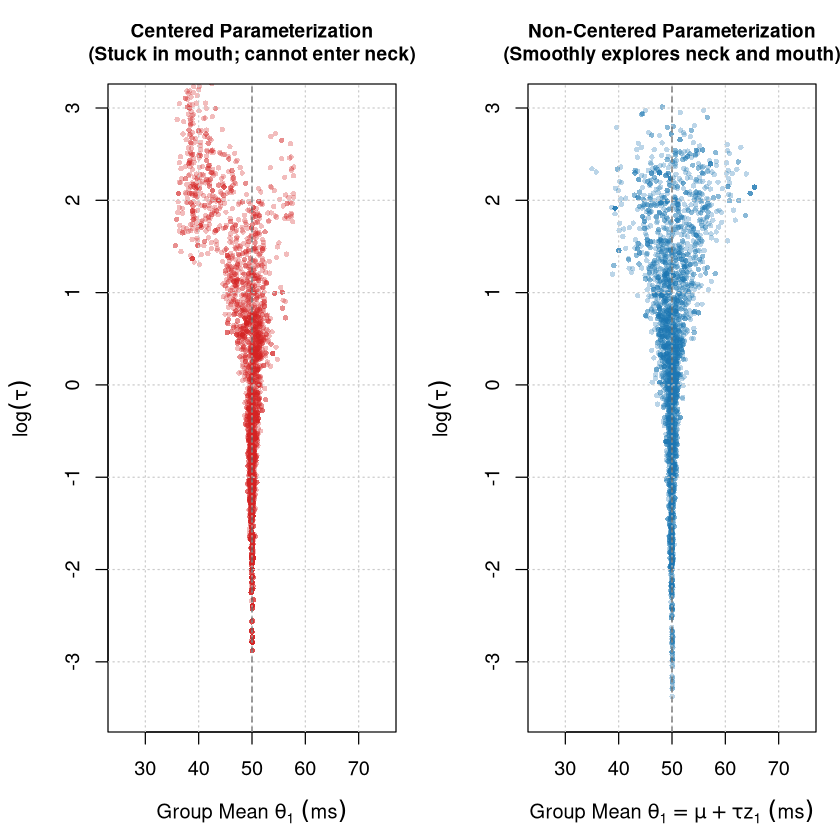

In [6]:
# ==============================================================================
# 🔴 Tier 3: Hierarchical MCMC — Centered vs Non-Centered Sampler & Funnel Plot
# ==============================================================================
set.seed(42)
n_iter <- 3000

# True parameters for observation
mu_ground <- 50.0
y_obs <- 54.0   # Observed sample mean for group 1
sigma_obs <- 10.0

# 1. Centered Sampler: state is (log_tau, theta)
trace_centered_lt <- numeric(n_iter)
trace_centered_th <- numeric(n_iter)

cur_lt <- 1.0
cur_th <- 50.0

log_post_centered <- function(lt, th) {
  tau <- exp(lt)
  lp_tau <- -0.5 * (lt / 1.5)^2
  lp_th <- -0.5 * ((th - mu_ground) / tau)^2 - lt
  ll <- -0.5 * ((y_obs - th) / sigma_obs)^2
  return(lp_tau + lp_th + ll)
}

for (i in 1:n_iter) {
  prop_lt <- cur_lt + rnorm(1, 0, 0.25)
  prop_th <- cur_th + rnorm(1, 0, 0.6)
  diff <- (log_post_centered(prop_lt, prop_th) -
           log_post_centered(cur_lt, cur_th))
  if (log(runif(1)) < diff) {
    cur_lt <- prop_lt
    cur_th <- prop_th
  }
  trace_centered_lt[i] <- cur_lt
  trace_centered_th[i] <- cur_th
}

# 2. Non-Centered Sampler: state is (log_tau, z)
trace_noncentered_lt <- numeric(n_iter)
trace_noncentered_th <- numeric(n_iter)

cur_lt <- 1.0
cur_z <- 0.0

log_post_noncentered <- function(lt, z) {
  tau <- exp(lt)
  th <- mu_ground + tau * z
  lp_tau <- -0.5 * (lt / 1.5)^2
  lp_z <- -0.5 * (z^2)
  ll <- -0.5 * ((y_obs - th) / sigma_obs)^2
  return(lp_tau + lp_z + ll)
}

for (i in 1:n_iter) {
  prop_lt <- cur_lt + rnorm(1, 0, 0.25)
  prop_z <- cur_z + rnorm(1, 0, 0.6)
  diff <- (log_post_noncentered(prop_lt, prop_z) -
           log_post_noncentered(cur_lt, cur_z))
  if (log(runif(1)) < diff) {
    cur_lt <- prop_lt
    cur_z <- prop_z
  }
  trace_noncentered_lt[i] <- cur_lt
  trace_noncentered_th[i] <- mu_ground + exp(cur_lt) * cur_z
}

# Visualization: Exposing Neal's Funnel
par(mfrow = c(1, 2), mar = c(4.5, 4.5, 3.5, 1))

plot(trace_centered_th, trace_centered_lt, col = rgb(0.84, 0.15, 0.15, 0.3),
     pch = 16, cex = 0.6, xlim = c(25, 75), ylim = c(-3.5, 3.0),
     xlab = expression(Group~Mean~theta[1]~(ms)), ylab = expression(log(tau)),
     main = "Centered Parameterization\n(Stuck in mouth; cannot enter neck)",
     cex.main = 0.95, font.main = 2)
grid(nx = NULL, ny = NULL, col = "gray80", lty = 3)
abline(v = mu_ground, col = "gray40", lty = 2)

plot(trace_noncentered_th, trace_noncentered_lt,
     col = rgb(0.12, 0.47, 0.71, 0.3),
     pch = 16, cex = 0.6, xlim = c(25, 75), ylim = c(-3.5, 3.0),
     xlab = expression(Group~Mean~theta[1] == mu + tau*z[1]~(ms)),
     ylab = expression(log(tau)),
     main = "Non-Centered Parameterization\n(Smoothly explores neck and mouth)",
     cex.main = 0.95, font.main = 2)
grid(nx = NULL, ny = NULL, col = "gray80", lty = 3)
abline(v = mu_ground, col = "gray40", lty = 2)


<details>
<summary><b>🔍 Click here to view the mathematical proof & geometric
explanation</b></summary>

**Mathematical Proof & Geometric Analysis**:
1. **The Gradient Singularity in Centered Parameterization**:
In the centered model, the gradient of the log-prior with respect to $\theta_j$
is:
$$\frac{\partial}{\partial \theta_j} \log p(\theta_j \mid \mu, \tau) =
-\frac{\theta_j - \mu}{\tau^2}$$
As $\tau \to 0$ (entering the neck of the funnel), the curvature
$\frac{1}{\tau^2} \to \infty$.
To avoid rejecting proposals, a random-walk proposal step size or HMC leapfrog
integrator must scale as $\mathcal{O}(\tau)$. Any step size $\epsilon$
calibrated
for the mouth ($\tau \approx 2$) will wildly overshoot the neck, yielding $0\%$
   acceptance.
2. **The Non-Centered Decoupling**:
   In the non-centered model:
   $$\frac{\partial}{\partial z_j} \log p(z_j) = -z_j$$
   The curvature is **constant and equal to $1.0$ everywhere**, completely
   independent of $\tau$!
3. **Rule of Thumb for Production Hierarchical Modeling**:
   - When data per group is **sparse ($n_j$ small)**: Use the **Non-Centered**
parameterization (prior geometry dominates, non-centered avoids the funnel).
   - When data per group is **dense ($n_j$ large)**: Use the **Centered**
     parameterization (likelihood dominates and pins $\theta_j$, rendering
     centered geometry well-conditioned).

</details>


---

## 🎓 Conclusion: The Hierarchical Bayes Advantage

Hierarchical models represent the pinnacle of Bayesian synthesis:
* **The Classical Failure**: No Pooling overfits small sample clusters; Complete
  Pooling ignores genuine systemic variance.
* **The Bayesian Solution**: Partial Pooling dynamically learns the population
  distribution from the collective data, allowing small groups to borrow
  statistical strength from large groups.
* **Stein's Paradox**: For $J \ge 3$ groups, shrinkage strictly dominates
  unpooled sample averages under total squared error loss.
* **Computational Mastery**: Non-centered parameterization eliminates Neal's
Funnel,
  unlocking robust MCMC and HMC sampling across hundreds of production clusters.

---
## 🧭 Course Navigation

* 🏠 **[Course Home & Master Syllabus](00_START_HERE.ipynb)**
* ⬅️ **Previous**: **[Ch 12: Bayesian Regression, Counts & GLMs](12_bayesian_regression_and_glms.ipynb)** *(Part III: Applied Modeling, Regression, Hierarchy & Model Comparison)*
* ➡️ **Next**: **[Ch 14: Marginal Likelihood & Occam's Razor](14_marginal_likelihood_and_model_comparison.ipynb)** *(Part III: Applied Modeling, Regression, Hierarchy & Model Comparison)*
* 🔄 **Companion Tracks for Chapter 13**: [📖 Conceptual](../conceptual/13_hierarchical_models_and_partial_pooling.ipynb) | [🤖 AI-Native](../ai/13_hierarchical_models_and_partial_pooling.ipynb) | [🐍 Python](../python/13_hierarchical_models_and_partial_pooling.ipynb) | [🔵 R](../r/13_hierarchical_models_and_partial_pooling.ipynb)
